# 07 · How an MLP works: forward, loss, backpropagation, update, from scratch

**Lecture:** *Working of MLP / ANN* (20-08-2026) · **Notes:** `../notes/07_working_of_mlp.md`

The lecture's eight steps, all in code:

**input → weighted sum → activation → … → prediction → loss → backpropagation (gradients) → update → repeat**

In this notebook you will:
1. Recompute the lecture's small examples (neuron z = 1.3, ReLU on [−2, 3], loss 0.357, update 2 → 1.95).
2. Build a 2-layer MLP in **plain NumPy** using **exactly the lecture's backpropagation formulas** (δ⁽²⁾ = Ŷ − Y, …).
3. **Prove those formulas are right**: compare them with numerical derivatives and with PyTorch's automatic gradients.
4. Train it on handwritten digits with mini-batches, counting **steps vs batches vs epochs**, with training, validation and test sets.
5. See **underfitting and overfitting**, and what the hidden neurons learned.

Runs in under a minute.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(0)

## 1 · The lecture's small examples

### One neuron: z = w·x + b, then a = f(z)

In [2]:
x = np.array([2, 3, 1]); w = np.array([0.5, 0.2, -0.4]); b = 0.1
z = w @ x + b
print(f"z = (2)(0.5) + (3)(0.2) + (1)(-0.4) + 0.1 = {z:.1f}   ->   ReLU(z) = {max(0, z):.1f}")
print("ReLU applied to Z = [-2, 3]:", np.maximum(0, np.array([-2, 3])))

z = (2)(0.5) + (3)(0.2) + (1)(-0.4) + 0.1 = 1.3   ->   ReLU(z) = 1.3
ReLU applied to Z = [-2, 3]: [0 3]


### Loss for Y = [1, 0], Ŷ = [0.7, 0.3], and one gradient-descent update

In [3]:
Y, Y_hat = np.array([1, 0]), np.array([0.7, 0.3])
print(f"L = -[1*log(0.7) + 0*log(0.3)] = {-(Y * np.log(Y_hat)).sum():.3f}")
w_old, grad, lr = 2.0, 0.5, 0.1
print(f"w_new = w - lr * dL/dw = {w_old} - {lr} * {grad} = {w_old - lr * grad}")
print("we SUBTRACT because the gradient points towards increasing loss")

L = -[1*log(0.7) + 0*log(0.3)] = 0.357
w_new = w - lr * dL/dw = 2.0 - 0.1 * 0.5 = 1.95
we SUBTRACT because the gradient points towards increasing loss


## 2 · A 2-layer MLP in NumPy, with the lecture's equations

| Forward | Backward (softmax + cross-entropy) |
|---|---|
| Z⁽¹⁾ = X W⁽¹⁾ + b⁽¹⁾ | δ⁽²⁾ = Ŷ − Y |
| A⁽¹⁾ = ReLU(Z⁽¹⁾) | ∂L/∂W⁽²⁾ = A⁽¹⁾ᵀ δ⁽²⁾,  ∂L/∂b⁽²⁾ = δ⁽²⁾ |
| Z⁽²⁾ = A⁽¹⁾ W⁽²⁾ + b⁽²⁾ | δ⁽¹⁾ = [δ⁽²⁾ W⁽²⁾ᵀ] ⊙ ReLU′(Z⁽¹⁾) |
| Ŷ = softmax(Z⁽²⁾) | ∂L/∂W⁽¹⁾ = Xᵀ δ⁽¹⁾,  ∂L/∂b⁽¹⁾ = δ⁽¹⁾ |
| L = −Σ y log ŷ | update: W ← W − η ∂L/∂W |

For a batch of m examples we average the loss, so the gradients get a factor 1/m and the bias gradients are **summed over the batch**.

In [4]:
def softmax(Z):
    Z = Z - Z.max(axis=1, keepdims=True)              # numerically stable (doesn't change the result)
    e = np.exp(Z)
    return e / e.sum(axis=1, keepdims=True)

class MLP:
    def __init__(self, n_in, n_hidden, n_out, seed=0):
        r = np.random.default_rng(seed)
        self.W1 = r.normal(0, np.sqrt(2 / n_in), (n_in, n_hidden)); self.b1 = np.zeros(n_hidden)      # He init (notebook 08)
        self.W2 = r.normal(0, np.sqrt(2 / n_hidden), (n_hidden, n_out)); self.b2 = np.zeros(n_out)

    def forward(self, X):
        self.X = X
        self.Z1 = X @ self.W1 + self.b1          # step 2: weighted sums (pre-activations)
        self.A1 = np.maximum(0, self.Z1)         # step 3: activation (ReLU)
        self.Z2 = self.A1 @ self.W2 + self.b2    # step 4: next layer
        self.Y_hat = softmax(self.Z2)            # step 5: output probabilities
        return self.Y_hat

    def loss(self, Y):                           # step 6: cross-entropy, averaged over the batch
        return -np.mean(np.sum(Y * np.log(self.Y_hat + 1e-12), axis=1))

    def backward(self, Y):                       # step 7: backpropagation (the lecture's formulas)
        m = len(Y)
        d2 = (self.Y_hat - Y) / m                          # delta(2) = Y_hat - Y   (/m: average over batch)
        self.dW2 = self.A1.T @ d2                          # dL/dW2 = A1^T delta(2)
        self.db2 = d2.sum(axis=0)                          # dL/db2 = delta(2)
        d1 = (d2 @ self.W2.T) * (self.Z1 > 0)              # delta(1) = [delta(2) W2^T] (*) ReLU'(Z1)
        self.dW1 = self.X.T @ d1                           # dL/dW1 = X^T delta(1)
        self.db1 = d1.sum(axis=0)                          # dL/db1 = delta(1)

    def step(self, lr):                          # step 8: gradient-descent update
        for p in ["W1", "b1", "W2", "b2"]:
            setattr(self, p, getattr(self, p) - lr * getattr(self, "d" + p))

net = MLP(4, 5, 3)
Xb = rng.normal(size=(6, 4)); Yb = np.eye(3)[rng.integers(0, 3, 6)]
net.forward(Xb); print("loss on a random batch:", round(net.loss(Yb), 4)); net.backward(Yb)
print("gradient shapes:", {k: getattr(net, k).shape for k in ["dW1", "db1", "dW2", "db2"]})

loss on a random batch: 1.0162
gradient shapes: {'dW1': (4, 5), 'db1': (5,), 'dW2': (5, 3), 'db2': (3,)}


## 3 · Are the formulas right? Two independent checks

**Check 1: numerical derivative.** Nudge one weight by ±ε, measure how the loss changes, and divide: **(L(w + ε) − L(w − ε)) / 2ε**. This is the definition of "how much the loss changes when a parameter changes slightly".

In [5]:
def numerical_grad(net, X, Y, name, idx, eps=1e-5):
    P = getattr(net, name); old = P[idx]
    P[idx] = old + eps; net.forward(X); lp = net.loss(Y)
    P[idx] = old - eps; net.forward(X); lm = net.loss(Y)
    P[idx] = old
    return (lp - lm) / (2 * eps)

net.forward(Xb); net.backward(Yb)
worst = 0
for name, idx in [("W1", (0, 0)), ("W1", (3, 4)), ("b1", (2,)), ("W2", (1, 2)), ("b2", (0,))]:
    analytic = getattr(net, "d" + name)[idx]; numeric = numerical_grad(net, Xb, Yb, name, idx)
    worst = max(worst, abs(analytic - numeric))
    print(f"{name}{list(idx)}: backprop {analytic:+.8f}   numerical {numeric:+.8f}")
print(f"largest difference: {worst:.1e}")

W1[0, 0]: backprop +0.15445220   numerical +0.15445220
W1[3, 4]: backprop -0.02160575   numerical -0.02160575
b1[2]: backprop -0.01735445   numerical -0.01735445
W2[1, 2]: backprop -0.12472377   numerical -0.12472377
b2[0]: backprop +0.11099402   numerical +0.11099402
largest difference: 1.4e-11


**Check 2: PyTorch's autograd** computes the gradients of the same network automatically (the chain rule done by the computer).

In [6]:
import torch
T = lambda a: torch.tensor(a, dtype=torch.float64, requires_grad=True)
W1, b1, W2, b2 = T(net.W1), T(net.b1), T(net.W2), T(net.b2)
Xt, Yt = torch.tensor(Xb), torch.tensor(Yb)
loss = -(Yt * torch.log_softmax(torch.relu(Xt @ W1 + b1) @ W2 + b2, dim=1)).sum(1).mean()
loss.backward()
net.forward(Xb); net.backward(Yb)
for name, t in [("W1", W1), ("b1", b1), ("W2", W2), ("b2", b2)]:
    print(f"{name}: max |backprop - autograd| = {np.abs(getattr(net, 'd' + name) - t.grad.numpy()).max():.1e}")

W1: max |backprop - autograd| = 2.8e-17
b1: max |backprop - autograd| = 3.1e-17
W2: max |backprop - autograd| = 2.8e-17
b2: max |backprop - autograd| = 2.8e-17


Both checks agree with the hand-derived formulas to many decimal places (differences at the level of floating-point rounding). The lecture's backpropagation equations are exactly what PyTorch's `loss.backward()` computes.

## 4 · Train it on handwritten digits

The scikit-learn digits: 8×8 images, so **64 inputs** → **64 hidden ReLU neurons** → **10 softmax outputs**. We split the data into training (learn weights), validation (watch for overfitting, choose settings) and test (final score, used once).

In [7]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
d = load_digits()
X_all = d.data / 16.0                                    # normalise pixels to 0..1 (lecture: why normalisation matters)
Y_all = np.eye(10)[d.target]                             # one-hot targets for categorical cross-entropy
X_tr, X_tmp, Y_tr, Y_tmp = train_test_split(X_all, Y_all, test_size=0.4, random_state=0, stratify=d.target)
X_va, X_te, Y_va, Y_te = train_test_split(X_tmp, Y_tmp, test_size=0.5, random_state=0, stratify=Y_tmp.argmax(1))
print("train", X_tr.shape, " validation", X_va.shape, " test", X_te.shape)

def accuracy(net, X, Y):
    return (net.forward(X).argmax(1) == Y.argmax(1)).mean()

def train(net, epochs=40, batch_size=128, lr=0.5, seed=0, verbose=True):
    r = np.random.default_rng(seed); steps = 0; hist = []
    for epoch in range(epochs):
        order = r.permutation(len(X_tr))
        for start in range(0, len(order), batch_size):           # one batch = one training step
            idx = order[start:start + batch_size]
            net.forward(X_tr[idx]); net.backward(Y_tr[idx]); net.step(lr)
            steps += 1
        net.forward(X_tr); tr_loss = net.loss(Y_tr)
        net.forward(X_va); va_loss = net.loss(Y_va)
        hist.append((tr_loss, va_loss, accuracy(net, X_tr, Y_tr), accuracy(net, X_va, Y_va)))
        if verbose and (epoch < 3 or (epoch + 1) % 10 == 0):
            print(f"epoch {epoch + 1:>2}: steps so far {steps:>3} | train loss {tr_loss:.3f} acc {hist[-1][2]:.1%} | val loss {va_loss:.3f} acc {hist[-1][3]:.1%}")
    return np.array(hist), steps

net = MLP(64, 64, 10)
hist, steps = train(net)
batches_per_epoch = int(np.ceil(len(X_tr) / 128))
print(f"\n{len(X_tr)} training images / batch size 128 = {batches_per_epoch} batches per epoch -> 40 epochs = {steps} weight updates")
print(f"TEST accuracy (looked at once, at the end): {accuracy(net, X_te, Y_te):.1%}")

train (1078, 64)  validation (359, 64)  test (360, 64)
epoch  1: steps so far   9 | train loss 1.385 acc 61.9% | val loss 1.413 acc 58.8%
epoch  2: steps so far  18 | train loss 0.823 acc 75.3% | val loss 0.860 acc 75.8%
epoch  3: steps so far  27 | train loss 0.518 acc 85.0% | val loss 0.566 acc 83.8%
epoch 10: steps so far  90 | train loss 0.178 acc 96.1% | val loss 0.205 acc 95.5%
epoch 20: steps so far 180 | train loss 0.096 acc 97.7% | val loss 0.153 acc 95.0%
epoch 30: steps so far 270 | train loss 0.069 acc 98.4% | val loss 0.125 acc 96.9%
epoch 40: steps so far 360 | train loss 0.053 acc 98.8% | val loss 0.115 acc 96.7%

1078 training images / batch size 128 = 9 batches per epoch -> 40 epochs = 360 weight updates
TEST accuracy (looked at once, at the end): 96.4%


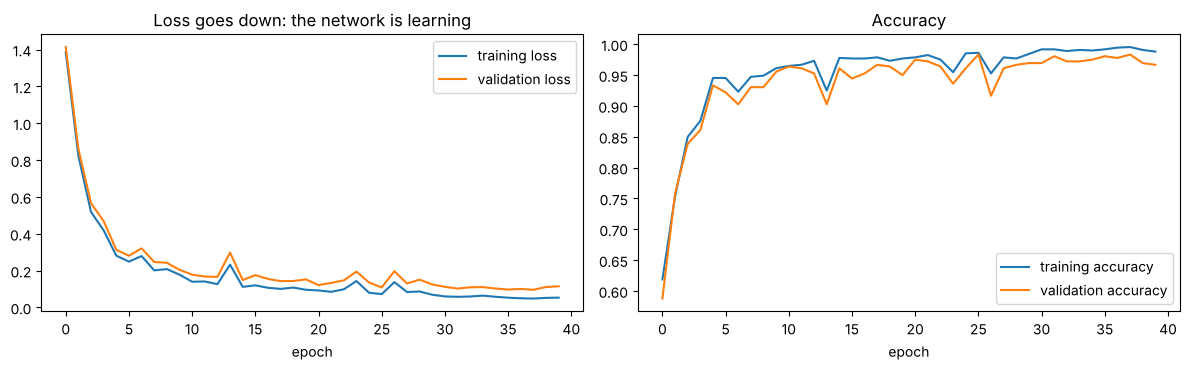

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(hist[:, 0], label="training loss"); axes[0].plot(hist[:, 1], label="validation loss"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].plot(hist[:, 2], label="training accuracy"); axes[1].plot(hist[:, 3], label="validation accuracy"); axes[1].set_xlabel("epoch"); axes[1].legend()
axes[0].set_title("Loss goes down: the network is learning"); axes[1].set_title("Accuracy")
plt.tight_layout(); plt.show()

### Steps vs batches vs epochs (the lecture's arithmetic)

In [9]:
for n, bs, ep in [(50_000, 128, 15), (50_000, 100, 10)]:
    per_epoch = int(np.ceil(n / bs))
    print(f"{n:,} examples, batch {bs}: {n / bs:.1f} -> {per_epoch} batches per epoch; {ep} epochs = {per_epoch * ep:,} weight updates")

50,000 examples, batch 128: 390.6 -> 391 batches per epoch; 15 epochs = 5,865 weight updates
50,000 examples, batch 100: 500.0 -> 500 batches per epoch; 10 epochs = 5,000 weight updates


Weights are updated **once per batch**, not once per epoch. With 50,000 examples, batch size 100 and 10 epochs, that's **5,000** updates, exactly the lecture's number. (50,000/128 = 390.6, so the last batch of each epoch is smaller: 391 batches.)

## 5 · Underfitting vs overfitting

In [10]:
results = []
for name, hidden, n_train, epochs in [("tiny network (2 hidden neurons)", 2, None, 40),
                                     ("good fit (64 hidden)", 64, None, 40),
                                     ("big network, only 60 training images", 256, 60, 400)]:
    global X_tr, Y_tr
    X_tr_full, Y_tr_full = X_tr, Y_tr
    if n_train:
        X_tr, Y_tr = X_tr[:n_train], Y_tr[:n_train]
    h, _ = train(MLP(64, hidden, 10), epochs=epochs, batch_size=32, lr=0.2, verbose=False)
    results.append((name, h[-1, 2], h[-1, 3]))
    X_tr, Y_tr = X_tr_full, Y_tr_full
for name, tr, va in results:
    gap = tr - va
    verdict = "UNDERFITTING (poor everywhere)" if tr < 0.85 else ("OVERFITTING (big train-validation gap)" if gap > 0.1 else "good generalisation")
    print(f"{name:<38} train {tr:.1%}  validation {va:.1%}  -> {verdict}")

tiny network (2 hidden neurons)        train 66.3%  validation 65.5%  -> UNDERFITTING (poor everywhere)
good fit (64 hidden)                   train 99.8%  validation 98.1%  -> good generalisation
big network, only 60 training images   train 100.0%  validation 86.4%  -> OVERFITTING (big train-validation gap)


- **Underfitting:** the model is too small, so it's poor on training **and** validation data.
- **Overfitting:** it memorised its few training images (100% on them) but does much worse on new ones.
- **Fixes:** more data, a smaller model, dropout, L1/L2, early stopping (notebook 05).

## 6 · What did the hidden neurons learn?
Each hidden neuron has 64 incoming weights, one per pixel, which we can draw as an 8×8 picture. Red pixels push the neuron up, blue push it down.

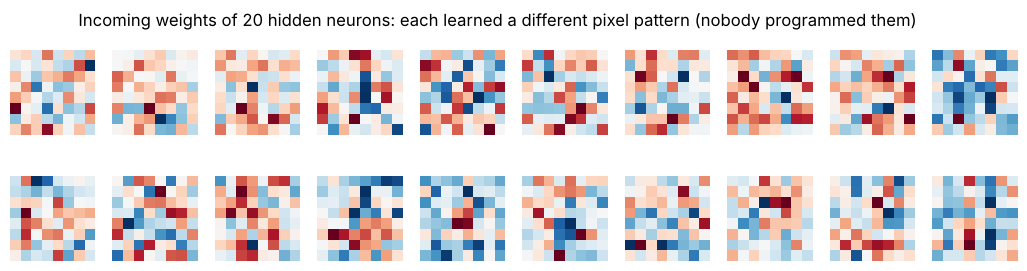

In [11]:
fig, axes = plt.subplots(2, 10, figsize=(13, 3))
for ax, i in zip(axes.ravel(), range(20)):
    ax.imshow(net.W1[:, i].reshape(8, 8), cmap="RdBu_r"); ax.axis("off")
fig.suptitle("Incoming weights of 20 hidden neurons: each learned a different pixel pattern (nobody programmed them)")
plt.show()

Each neuron ended up with a **different** pattern of positive and negative pixel weights. At 8×8 pixels and only 40 epochs they look noisy, not like neat pen strokes, yet together they are enough for about 96% test accuracy. The network doesn't learn rules like "if the top is closed, it's a 9". It learns **numbers** (weights) that turn neurons into useful detectors, because that lowers the loss. **Training is an optimisation problem: find the weights and biases that minimise the loss.**

### Backpropagation vs the optimizer (don't mix them up)
- **Backpropagation** computes the **gradients** (section 3).
- The **optimizer** decides how to **use** them: plain gradient descent (our `step`), or **Adam**, which keeps running averages of the gradients and their squares to adapt each weight's step size.

| Forward propagation | Backward propagation |
|---|---|
| input → output | loss → earlier layers |
| computes predictions | computes gradients |
| uses weights, biases, activations | uses the loss gradient and activation **derivatives** |
| ends with the loss | starts from the loss |
| "what did we predict?" | "how should we change?" |

## ✅ Check yourself
1. Compute a neuron: x = (1, −1, 2), w = (0.3, 0.5, 0.1), b = −0.2, ReLU. *(z = 0.3 − 0.5 + 0.2 − 0.2 = −0.2 → output 0)*
2. In softmax + cross-entropy, what is δ at the output? *(Ŷ − Y)*
3. Why does the hidden-layer δ⁽¹⁾ multiply by ReLU′(Z⁽¹⁾)? *(chain rule through the activation; neurons with negative input pass no gradient)*
4. 60,000 examples, batch 200, 5 epochs: how many weight updates? *(300 per epoch × 5 = 1,500)*
5. Which data set is used to choose hyper-parameters, and which only once at the end? *(validation; test)*
6. Backpropagation vs optimizer? *(backprop computes gradients; the optimizer turns them into weight updates)*